# 08 - Stress test: macro scenarios and probability-weighted ECL

The PD model has no macroeconomic variables, since the data covers a single period. Scenario PDs are therefore derived by shifting each loan's PD on the log-odds scale, calibrated so the portfolio average PD reaches an assumed target per scenario. Ranking between borrowers is preserved. Loans are re-staged in each scenario, so ECL rises from both higher PDs and migration to Stage 2.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.ecl import compute_ecl, lifetime_pd, assign_stage
from src.stress import shift_pd, calibrate_delta

portfolio = pd.read_parquet("../data/processed/portfolio_staged.parquet")
term_years = portfolio["CREDIT_TERM"].fillna(portfolio["CREDIT_TERM"].median()) / 12

SCENARIOS = {
    "Base":    {"target_pd": None,  "weight": 0.60},   # None = today's PDs unchanged
    "Adverse": {"target_pd": 0.11,  "weight": 0.30},
    "Severe":  {"target_pd": 0.14,  "weight": 0.10},
}

def run_scenario(pd_base, target_pd):
    delta = 0.0 if target_pd is None else calibrate_delta(pd_base, target_pd)
    pd_s = shift_pd(pd_base, delta)
    stage = assign_stage(pd_s)
    ecl_12m = compute_ecl(pd_s, portfolio["EAD"])
    ecl_life = compute_ecl(lifetime_pd(pd_s, term_years), portfolio["EAD"])
    ecl = np.where(stage == 2, ecl_life, ecl_12m)
    return delta, pd_s, stage, ecl

rows = []
for name, s in SCENARIOS.items():
    delta, pd_s, stage, ecl = run_scenario(portfolio["PD"], s["target_pd"])
    portfolio[f"ECL_{name.upper()}"] = ecl
    rows.append({"scenario": name, "weight": s["weight"], "delta": delta,
                 "mean_pd": pd_s.mean(), "stage2_share": (stage == 2).mean(),
                 "ecl": ecl.sum()})

results = pd.DataFrame(rows).set_index("scenario")
results["vs_base"] = results["ecl"] / results.loc["Base", "ecl"] - 1
print(results.style.format({"weight": "{:.0%}", "delta": "{:.3f}", "mean_pd": "{:.2%}",
                            "stage2_share": "{:.1%}", "ecl": "{:,.0f}",
                            "vs_base": "{:.1%}"}).to_string())

weighted_ecl = (results["ecl"] * results["weight"]).sum()
print(f"\nProbability-weighted ECL: {weighted_ecl:,.0f} "
      f"({weighted_ecl / results.loc['Base', 'ecl'] - 1:+.1%} vs base)")

 weight delta mean_pd stage2_share ecl vs_base
scenario      
Base 60% 0.000 8.07% 7.3% 6,728,246,276 0.0%
Adverse 30% 0.372 11.00% 14.1% 9,758,570,010 45.0%
Severe 10% 0.678 14.00% 22.2% 13,115,092,430 94.9%


Probability-weighted ECL: 8,276,028,011 (+23.0% vs base)


## Scenarios

| Scenario | Average PD | Weight | Narrative |
|---|---|---|---|
| Base | 8.07% (current) | 60% | Current economic conditions |
| Adverse | 11% | 30% | Higher interest rates and rising unemployment |
| Severe | 14% | 10% | Deep recession with sharply higher unemployment |

**Justification and limitations:** the targets and weights are assumptions. The PD model contains no macroeconomic variables, and the data covers a single period, so the link between macro variables and PD cannot be estimated. A bank would derive scenario PDs from a satellite model linking historical default rates to variables such as interest rates, unemployment, GDP and house prices. Each loan's PD is shifted on the log-odds scale, which keeps PDs between 0 and 1 and preserves the model's ranking.

**Scenario results:** ECL rises faster than PD. In the adverse scenario, average PD rises by 36% (8.07% to 11.00%) but ECL by 45%; in the severe scenario, PD rises by 73% (to 14.00%) and ECL nearly doubles (+95%). The difference comes from stage migration: the Stage 2 share rises from 7.3% to 14.1% (adverse) and 22.2% (severe), moving those loans from 12-month to lifetime ECL.

**Probability-weighted ECL:** 8.28 billion, 23% above the base scenario (6.73 billion). Because losses grow non-linearly in bad scenarios, the weighted ECL exceeds the ECL of the most likely scenario. This is why IFRS 9 requires probability-weighted scenarios rather than a single central estimate.

## Separate the two effects

 pd_effect migration_effect
scenario  
Base 0 0
Adverse 2,300,813,566 729,510,168
Severe 4,626,152,976 1,760,693,179



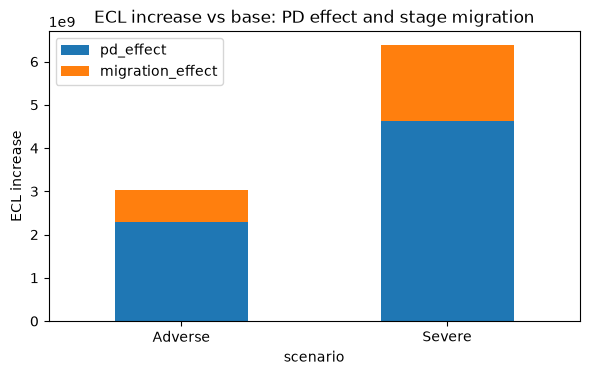

In [2]:
base_stage = portfolio["STAGE"].values
rows = []
for name, s in SCENARIOS.items():
    _, pd_s, _, ecl_full = run_scenario(portfolio["PD"], s["target_pd"])
    ecl_12m = compute_ecl(pd_s, portfolio["EAD"])
    ecl_life = compute_ecl(lifetime_pd(pd_s, term_years), portfolio["EAD"])
    ecl_fixed = np.where(base_stage == 2, ecl_life, ecl_12m).sum()
    rows.append({"scenario": name,
                 "pd_effect": ecl_fixed - results.loc["Base", "ecl"],
                 "migration_effect": ecl_full.sum() - ecl_fixed})

effects = pd.DataFrame(rows).set_index("scenario")
print(effects.style.format("{:,.0f}").to_string())

effects.drop("Base").plot(kind="bar", stacked=True, figsize=(6, 4),
                          title="ECL increase vs base: PD effect and stage migration")
plt.ylabel("ECL increase")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Decomposition:** most of the ECL increase comes from higher PDs (76% in the adverse scenario, 72% in the severe). Stage migration adds the rest, and its share grows with the severity of the scenario: the migration effect more than doubles from adverse (0.73 billion) to severe (1.76 billion). The worse the downturn, the more loans cross the SICR threshold, which is the source of the cliff effect and of IFRS 9's procyclicality.

## The LGD sensitivity

In [3]:
LGDS = [0.45, 0.60, 0.75]
lgd_rows = []
for lgd in LGDS:
    scale = lgd / 0.45
    lgd_rows.append({
        "lgd": lgd,
        "base_ecl": results.loc["Base", "ecl"] * scale,
        "weighted_ecl": weighted_ecl * scale,
        "coverage_weighted": weighted_ecl * scale / portfolio["EAD"].sum(),
    })

lgd_table = pd.DataFrame(lgd_rows)
print(lgd_table.style.format({"lgd": "{:.0%}", "base_ecl": "{:,.0f}",
                              "weighted_ecl": "{:,.0f}",
                              "coverage_weighted": "{:.2%}"}).to_string())

 lgd base_ecl weighted_ecl coverage_weighted
0 45% 6,728,246,276 8,276,028,011 4.49%
1 60% 8,970,995,034 11,034,704,015 5.99%
2 75% 11,213,743,793 13,793,380,019 7.49%



**LGD sensitivity:** ECL is proportional to LGD. Raising LGD from 45% to 75% increases the probability-weighted ECL from 8.28 to 13.79 billion (+67%), and coverage from 4.49% to 7.49%. This effect is almost as large as the severe scenario's (6.4 billion above base), so the LGD assumption is a major source of uncertainty. Real LGDs for unsecured consumer loans are often above 45%, and LGDs typically rise in downturns along with PDs, which would compound the scenario effects. A bank would estimate LGD from historical recovery data, including a downturn LGD for stress conditions.

## Stress test summary

| | ECL | vs base |
|---|---|---|
| Base | 6.73 billion | — |
| Adverse | 9.76 billion | +45% |
| Severe | 13.12 billion | +95% |
| Probability-weighted (LGD 45%) | 8.28 billion | +23% |
| Probability-weighted (LGD 75%) | 13.79 billion | +105% |

Key findings: ECL rises faster than PD because of stage migration; the migration effect grows with scenario severity; and the LGD assumption has an effect comparable to a severe recession.